# EDA 01 — SkillSpan (Problem 1 data)

**Dataset:** SkillSpan (Zhang et al., NAACL 2022) — job-posting sentences annotated by domain experts with
*skill* spans (what a person can do) and *knowledge* spans (what a person knows), BIO-tagged per token.
Two sources are released: **tech** (software/IT postings) and **house** (a mixed in-house set, mostly
research/academic postings). Source: `kris927b/SkillSpan` on GitHub (CC BY 4.0).

This notebook answers the rubric's EDA questions for Problem 1: record counts, schema, missing values,
token/sequence statistics, vocabulary, label distribution, span lengths, n-grams, POS patterns and entities,
and it decides the **label scheme** used for training (merged vs separate taggers).

In [1]:
import json, os, sys, collections, itertools, re
from pathlib import Path
import numpy as np, pandas as pd
import plotly.express as px, plotly.graph_objects as go
os.environ["SMC_SOURCE"] = "notebooks/01_eda_skillspan"
from src.utils import viz; viz.setup()
from src.utils.config import ROOT
from src.utils.io import write_json
from src.utils.text import bio_to_spans
from src.data import skillspan as ss

data = ss.load_all()
{k: len(v) for k, v in data.items()}

{'train': 4800, 'dev': 3174, 'test': 3569}

## 1. Schema and record counts

In [2]:
rows = [dict(r, n_tokens=len(r["tokens"])) for split in data for r in data[split]]
df = pd.DataFrame(rows)[["sid", "split", "source", "n_tokens", "tokens", "tags_skill", "tags_knowledge"]]
print("schema:", {c: str(df[c].dtype) for c in df.columns})
counts = df.groupby(["split", "source"]).size().unstack(fill_value=0)
counts["total"] = counts.sum(axis=1)
counts

schema: {'sid': 'str', 'split': 'str', 'source': 'str', 'n_tokens': 'int64', 'tokens': 'object', 'tags_skill': 'object', 'tags_knowledge': 'object'}


source,house,tech,total
split,,,
dev,1018,2156,3174
test,1283,2286,3569
train,1667,3133,4800


In [3]:
fig = px.bar(df.groupby(["split", "source"]).size().reset_index(name="sentences"),
             x="split", y="sentences", color="source", barmode="group", text="sentences",
             category_orders={"split": ["train", "dev", "test"], "source": ["tech", "house"]},
             title="SkillSpan sentences per split and source")
fig.update_traces(textposition="outside")
fig.update_layout(yaxis_title="sentences", xaxis_title="")
viz.save_fig(fig, "eda01_sentences_by_split_source", "SkillSpan: sentences per split (train 4,800 / dev 3,174 / test 3,569), coloured by source (tech vs house).")
fig

## 2. Missing values, placeholders and label sanity
The data has no null fields; the only "missing" content is **de-identification placeholders** such as
`<ORGANIZATION>`, `<ADDRESS>`, `<EMAIL>` left by the GDPR scrubbing, which appear as ordinary tokens.

In [4]:
placeholder = collections.Counter(t for toks in df["tokens"] for t in toks if re.fullmatch(r"<[A-Z_]+>", t))
null_check = {c: int(df[c].isna().sum()) for c in ["tokens", "tags_skill", "tags_knowledge", "source"]}
len_mismatch = int(sum(len(r["tokens"]) != len(r["tags_skill"]) or len(r["tokens"]) != len(r["tags_knowledge"]) for r in rows))
tagsets = {"skill": sorted({t for ts in df["tags_skill"] for t in ts}), "knowledge": sorted({t for ts in df["tags_knowledge"] for t in ts})}
print("nulls:", null_check, "| token/tag length mismatches:", len_mismatch)
print("tag sets:", tagsets)
print("placeholder tokens:", placeholder.most_common(8))
sent_with_placeholder = df["tokens"].map(lambda toks: any(re.fullmatch(r"<[A-Z_]+>", t) for t in toks)).mean()
print(f"share of sentences containing a placeholder: {sent_with_placeholder:.1%}")

nulls: {'tokens': 0, 'tags_skill': 0, 'tags_knowledge': 0, 'source': 0} | token/tag length mismatches: 0
tag sets: {'skill': ['B', 'I', 'O'], 'knowledge': ['B', 'I', 'O']}
placeholder tokens: [('<ORGANIZATION>', 3648), ('<LOCATION>', 1647), ('<CONTACT>', 627), ('<NAME>', 387), ('<ADDRESS>', 220), ('<DESCRIPTION>', 39), ('<PROFESSION>', 35), ('<SIZE>', 31)]
share of sentences containing a placeholder: 19.7%


## 3. Token and sequence-length statistics, vocabulary

In [5]:
stats = {split: ss.span_stats(data[split]) for split in data}
tok_table = pd.DataFrame({s: {"sentences": v["sentences"], "tokens": v["tokens"], "avg tokens/sentence": round(v["avg_tokens_per_sentence"], 1),
                               "vocab size": v["vocab_size"], "all-O sentences": v["all_O_sentences"], "all-O share": f"{v['all_O_share']:.1%}",
                               "skill spans": v["skill_spans"], "knowledge spans": v["knowledge_spans"]} for s, v in stats.items()}).T
tok_table

,sentences,tokens,avg tokens/sentence,vocab size,all-O sentences,all-O share,skill spans,knowledge spans
train,4800,93453,19.5,8219,3216,67.0%,2221,2807
dev,3174,40057,12.6,5215,2260,71.2%,1070,1044
test,3569,42786,12.0,5237,2595,72.7%,1091,1157


In [6]:
q = df["n_tokens"].quantile([0.5, 0.9, 0.95, 0.99, 1.0])
print("tokens per sentence quantiles:", q.round(1).to_dict())
fig = px.histogram(df, x="n_tokens", color="source", nbins=60, barmode="overlay", opacity=0.75,
                   category_orders={"source": ["tech", "house"]}, title="Tokens per sentence (max_length=128 covers >99%)")
fig.update_layout(xaxis_title="tokens per sentence", yaxis_title="sentences", bargap=0.05)
fig.add_vline(x=128, line_dash="dot", line_color=viz.INK["muted"], annotation_text="max_length 128", annotation_position="top right")
viz.save_fig(fig, "eda01_tokens_per_sentence", "Tokens per sentence by source; 99% of sentences are shorter than the 128-token training limit.")
fig

tokens per sentence quantiles: {0.5: 11.0, 0.9: 30.0, 0.95: 39.0, 0.99: 82.6, 1.0: 748.0}


## 4. Label distribution and the skill/knowledge overlap decision
SkillSpan has **two** tag columns. If a token is rarely tagged in both, one merged tagger with five labels
(O, B-SKILL, I-SKILL, B-KNOW, I-KNOW) is simpler and loses almost nothing; otherwise we train one tagger per column.

In [7]:
overlap = {split: ss.tag_overlap_stats(data[split]) for split in data}
ov = pd.DataFrame(overlap).T
ov["overlap_share_of_tagged"] = ov["overlap_share_of_tagged"].map(lambda x: f"{x:.2%}")
print(ov)
total_overlap = sum(v["tokens_tagged_both"] for v in overlap.values()) / sum(v["tokens_tagged_any"] for v in overlap.values())
label_scheme = "merged" if total_overlap < 0.01 else "separate"
print(f"\nTokens tagged as BOTH skill and knowledge: {total_overlap:.2%} of tagged tokens -> label scheme = {label_scheme.upper()}")

       tokens_tagged_skill  tokens_tagged_knowledge  tokens_tagged_both  \
train              10071.0                   5565.0               347.0   
dev                 4867.0                   2006.0               106.0   
test                4226.0                   2088.0                34.0   

       tokens_tagged_any overlap_share_of_tagged  
train            15289.0                   2.27%  
dev               6767.0                   1.57%  
test              6280.0                   0.54%  

Tokens tagged as BOTH skill and knowledge: 1.72% of tagged tokens -> label scheme = SEPARATE


In [8]:
tag_counts = []
for split in data:
    c = collections.Counter(t for r in data[split] for t in ss.record_labels(r, "merged"))
    for k, v in c.items():
        tag_counts.append({"split": split, "tag": k, "tokens": v})
tc = pd.DataFrame(tag_counts)
tc_p = tc.pivot(index="tag", columns="split", values="tokens").fillna(0).astype(int).loc[ss.MERGED_LABELS]
tc_p["share_train"] = (tc_p["train"] / tc_p["train"].sum()).map(lambda x: f"{x:.1%}")
tc_p

split,dev,test,train,share_train
tag,,,,
O,33290,36506,78164,83.6%
B-SKILL,1070,1090,2221,2.4%
I-SKILL,3797,3136,7850,8.4%
B-KNOW,1044,1157,2807,3.0%
I-KNOW,856,897,2411,2.6%


## 5. Span lengths

In [9]:
span_rows = []
for split in data:
    for r in data[split]:
        for typ, s, e, text in bio_to_spans(r["tokens"], ss.record_labels(r, "merged")):
            span_rows.append({"split": split, "source": r["source"], "type": "skill" if typ == "SKILL" else "knowledge", "len": e - s, "text": text})
spans = pd.DataFrame(span_rows)
spans.groupby("type")["len"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
knowledge,5008.0,1.83,1.22,1.0,1.0,1.0,2.0,12.0
skill,4382.0,4.37,2.81,1.0,2.0,4.0,6.0,23.0


In [10]:
fig = px.histogram(spans[spans["len"] <= 20], x="len", color="type", barmode="group", nbins=20,
                   category_orders={"type": ["skill", "knowledge"]}, title="Span length in tokens: skills are long phrases, knowledge is short")
fig.update_layout(xaxis_title="span length (tokens)", yaxis_title="spans", bargap=0.15)
viz.save_fig(fig, "eda01_span_length_hist", "Span length distribution (tokens): skill spans are multi-word verb phrases (median 4), knowledge spans are mostly 1–2 tokens.")
fig

In [11]:
punct_end = spans["text"].str.contains(r"\s[.,;:]$", regex=True).mean()
print(f"Annotation quirk: {punct_end:.1%} of spans end with a punctuation token (e.g. 'obstetrics .'); kept as-is because the benchmark scores exact boundaries.")

Annotation quirk: 0.2% of spans end with a punctuation token (e.g. 'obstetrics .'); kept as-is because the benchmark scores exact boundaries.


## 6. Most frequent skill and knowledge phrases (train)

In [12]:
def top_phrases(typ, n=30):
    s = spans[(spans["split"] == "train") & (spans["type"] == typ)]["text"].str.lower().str.replace(r"\s+[.,;:]$", "", regex=True)
    return s.value_counts().head(n).rename_axis("phrase").reset_index(name="count")

top_sk, top_kn = top_phrases("skill"), top_phrases("knowledge")
fig = px.bar(top_sk.iloc[::-1], x="count", y="phrase", orientation="h", title="Top 30 skill phrases (train)")
fig.update_layout(height=760, yaxis_title="", xaxis_title="occurrences")
viz.save_fig(fig, "eda01_top_skill_phrases", "The 30 most frequent skill phrases in the training split — dominated by soft skills ('communication skills', 'team player').", height=760)
fig

In [13]:
fig = px.bar(top_kn.iloc[::-1], x="count", y="phrase", orientation="h", title="Top 30 knowledge phrases (train)")
fig.update_traces(marker_color=viz.PALETTE[1])
fig.update_layout(height=760, yaxis_title="", xaxis_title="occurrences")
viz.save_fig(fig, "eda01_top_knowledge_phrases", "The 30 most frequent knowledge phrases in the training split — programming languages, frameworks and degrees.", height=760)
fig

## 7. Linguistic features: POS patterns of spans, n-grams by source, named entities (spaCy)

In [14]:
import spacy
nlp = spacy.load("en_core_web_sm", disable=["lemmatizer"])
train_rows = data["train"]
docs = list(nlp.pipe([" ".join(r["tokens"]) for r in train_rows], batch_size=256))

def pos_pattern(doc, start, end):
    # map token offsets: SkillSpan tokens are whitespace-separated, spaCy may re-tokenize; align by char offsets
    return None

pat_rows = []
ent_rows = []
for r, doc in zip(train_rows, docs):
    # char offsets of each SkillSpan token in the joined string
    offs, pos = [], 0
    for t in r["tokens"]:
        offs.append((pos, pos + len(t))); pos += len(t) + 1
    tok_pos = {}
    for st in doc:
        tok_pos.setdefault(st.idx, st.pos_)
    for typ, s, e, text in bio_to_spans(r["tokens"], ss.record_labels(r, "merged")):
        tags = [tok_pos.get(offs[i][0], "X") for i in range(s, e)]
        tags = [t for t in tags if t != "PUNCT"] or ["PUNCT"]
        pat_rows.append({"type": "skill" if typ == "SKILL" else "knowledge", "pattern": "+".join(tags[:4]) + ("+…" if len(tags) > 4 else "")})
    for ent in doc.ents:
        ent_rows.append({"source": r["source"], "label": ent.label_, "text": ent.text})
pat = pd.DataFrame(pat_rows)
top_pat = (pat.groupby(["type", "pattern"]).size().reset_index(name="spans")
           .sort_values("spans", ascending=False).groupby("type").head(10))
top_pat

,type,pattern,spans
120,knowledge,PROPN,851
49,knowledge,NOUN,410
81,knowledge,NOUN+NOUN,316
154,knowledge,PROPN+PROPN,204
13,knowledge,ADJ+NOUN,175
282,skill,NOUN,137
203,skill,ADJ,124
552,skill,VERB+NOUN,91
430,skill,VERB+ADJ+NOUN,91
335,skill,NOUN+NOUN,85


In [15]:
fig = px.bar(top_pat.sort_values("spans"), x="spans", y="pattern", color="type", orientation="h", barmode="group",
             category_orders={"type": ["skill", "knowledge"]}, title="Top POS patterns of annotated spans (train, spaCy)")
fig.update_layout(height=640, yaxis_title="", xaxis_title="spans")
viz.save_fig(fig, "eda01_pos_patterns", "Part-of-speech patterns of spans: skills are VERB+… phrases or NOUN+NOUN ('communication skills'); knowledge is PROPN/NOUN heads.", height=640)
fig

In [16]:
STOP = set("the a an and or of to in with for on at by is are be as our you your we will this that from".split())
def ngrams(rows, n=2, top=15):
    c = collections.Counter()
    for r in rows:
        toks = [t.lower() for t in r["tokens"] if t.isalpha() and t.lower() not in STOP]
        c.update(zip(*[toks[i:] for i in range(n)]))
    return pd.DataFrame([{"ngram": " ".join(k), "count": v} for k, v in c.most_common(top)])
bi = pd.concat([ngrams([r for r in train_rows if r["source"] == s]).assign(source=s) for s in ["tech", "house"]])
fig = px.bar(bi.sort_values("count"), x="count", y="ngram", color="source", facet_col="source", orientation="h",
             facet_col_spacing=0.16, category_orders={"source": ["tech", "house"]}, title="Top 15 bigrams by source (train, stop-words removed)")
fig.update_yaxes(matches=None, showticklabels=True, title="")
fig.update_xaxes(matches=None)
fig.update_layout(height=620, showlegend=False)
viz.save_fig(fig, "eda01_ngrams_tech_vs_house", "Top bigrams per source: tech postings are about software development, experience and flexible working; house postings mix application boilerplate ('further information', 'please contact') with business domains ('supply chain', 'project management').", height=620)
fig

In [17]:
ents = pd.DataFrame(ent_rows)
ent_counts = ents[~ents["text"].str.contains("<")].groupby(["source", "label"]).size().reset_index(name="entities")
ent_top = ent_counts.sort_values("entities", ascending=False).groupby("source").head(8)
fig = px.bar(ent_top, x="label", y="entities", color="source", barmode="group", category_orders={"source": ["tech", "house"]},
             title="Named-entity labels found by spaCy (train, placeholders excluded)")
fig.update_layout(xaxis_title="", yaxis_title="entities")
viz.save_fig(fig, "eda01_entities", "spaCy entity labels in SkillSpan sentences: ORG/GPE are mostly scrubbed to placeholders; DATE and CARDINAL ('3+ years') dominate what remains.")
fig

## 8. A tagged example (for the slides)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


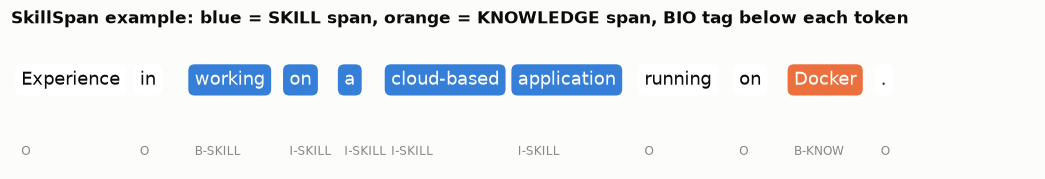

In [18]:
import matplotlib.pyplot as plt
ex = next(r for r in data["train"] if 10 <= len(r["tokens"]) <= 16 and any(t != "O" for t in r["tags_skill"]) and any(t != "O" for t in r["tags_knowledge"]) and "<" not in " ".join(r["tokens"]))
labels = ss.record_labels(ex, "merged")
fig, ax = plt.subplots(figsize=(12, 1.6)); ax.axis("off"); ax.grid(False)
x = 0.01
colors = {"SKILL": viz.PALETTE[0], "KNOW": viz.PALETTE[1]}
for tok, lab in zip(ex["tokens"], labels):
    typ = lab.split("-")[1] if "-" in lab else None
    bbox = dict(boxstyle="round,pad=0.35", fc=colors[typ] if typ else "#ffffff", ec=colors[typ] if typ else viz.INK["axis"], alpha=0.95 if typ else 1)
    t = ax.text(x, 0.65, tok, fontsize=12, color="white" if typ else viz.INK["primary"], bbox=bbox, transform=ax.transAxes, va="center")
    ax.text(x, 0.12, lab, fontsize=8, color=viz.INK["muted"], transform=ax.transAxes, va="center")
    x += 0.0078 * len(tok) + 0.038
ax.set_title("SkillSpan example: blue = SKILL span, orange = KNOWLEDGE span, BIO tag below each token", loc="left", fontsize=11)
viz.save_fig(fig, "eda01_tagged_example", "A SkillSpan sentence with its merged BIO tags (blue = skill, orange = knowledge).")
plt.show()

## 9. Summary

In [19]:
summary = {
    "record_counts": {s: v["sentences"] for s, v in stats.items()},
    "by_split_source": {f"{s}/{src}": int(n) for (s, src), n in df.groupby(["split", "source"]).size().items()},
    "missing_values": null_check, "length_mismatches": len_mismatch,
    "placeholder_share_of_sentences": round(float(sent_with_placeholder), 4),
    "tokens_per_sentence_quantiles": {str(k): float(v) for k, v in q.items()},
    "vocab_size_train": stats["train"]["vocab_size"],
    "all_O_share": {s: round(v["all_O_share"], 4) for s, v in stats.items()},
    "spans": {s: {"skill": v["skill_spans"], "knowledge": v["knowledge_spans"]} for s, v in stats.items()},
    "span_len_median": spans.groupby("type")["len"].median().to_dict(),
    "span_len_mean": spans.groupby("type")["len"].mean().round(2).to_dict(),
    "overlap_share_of_tagged_tokens": round(float(total_overlap), 5),
    "label_scheme_decision": label_scheme,
    "spans_ending_with_punctuation_share": round(float(punct_end), 4),
    "top_skill_phrases": top_sk.head(10).to_dict("records"),
    "top_knowledge_phrases": top_kn.head(10).to_dict("records"),
}
write_json(summary, "results/eda/skillspan_summary.json")
print(json.dumps({k: v for k, v in summary.items() if k not in ("top_skill_phrases", "top_knowledge_phrases")}, indent=1))
all_o_overall = sum(v["all_O_sentences"] for v in stats.values()) / sum(v["sentences"] for v in stats.values())
print(f"""
THREE MOST IMPORTANT FINDINGS
1. {all_o_overall:.0%} of all sentences contain no span at all (headers, benefits, boilerplate) -> the tagger must learn to
   stay silent; we report false positives on all-O sentences separately.
2. Skill spans are long verb phrases (median {spans[spans.type=='skill']['len'].median():.0f} tokens, mean {spans[spans.type=='skill']['len'].mean():.1f}), knowledge spans are short noun
   phrases (median {spans[spans.type=='knowledge']['len'].median():.0f}) -> boundary errors will dominate skill-span F1, so we report loose (overlap) F1 next to strict F1.
3. {total_overlap:.1%} of tagged tokens carry BOTH a skill and a knowledge tag -> {'above' if total_overlap >= 0.01 else 'below'} the 1% threshold in the plan, so the
   label scheme is '{label_scheme.upper()}' ({'one tagger per column, as in the SkillSpan paper' if label_scheme=='separate' else 'one merged 5-label tagger'}); recorded in results/eda/skillspan_summary.json
   and read by src/p1_extract/train_tagger.py.
""")

{
 "record_counts": {
  "train": 4800,
  "dev": 3174,
  "test": 3569
 },
 "by_split_source": {
  "dev/house": 1018,
  "dev/tech": 2156,
  "test/house": 1283,
  "test/tech": 2286,
  "train/house": 1667,
  "train/tech": 3133
 },
 "missing_values": {
  "tokens": 0,
  "tags_skill": 0,
  "tags_knowledge": 0,
  "source": 0
 },
 "length_mismatches": 0,
 "placeholder_share_of_sentences": 0.1966,
 "tokens_per_sentence_quantiles": {
  "0.5": 11.0,
  "0.9": 30.0,
  "0.95": 39.0,
  "0.99": 82.57999999999993,
  "1.0": 748.0
 },
 "vocab_size_train": 8219,
 "all_O_share": {
  "train": 0.67,
  "dev": 0.712,
  "test": 0.7271
 },
 "spans": {
  "train": {
   "skill": 2221,
   "knowledge": 2807
  },
  "dev": {
   "skill": 1070,
   "knowledge": 1044
  },
  "test": {
   "skill": 1091,
   "knowledge": 1157
  }
 },
 "span_len_median": {
  "knowledge": 1.0,
  "skill": 4.0
 },
 "span_len_mean": {
  "knowledge": 1.83,
  "skill": 4.37
 },
 "overlap_share_of_tagged_tokens": 0.01719,
 "label_scheme_decision": "sepa